In [1]:
import scanpy as sc
import numpy as np
import pandas as pd
from glob import glob
import torch

from model import VAE, loss
from utils import EarlyStop
import torch.nn.functional as F
import os, time, tqdm

from sklearn.neighbors import NearestNeighbors
from scipy import spatial
import spatialdata_preprocessing
import slda 

## Extract a cell x gene count matrix from the original data

Can skip this if a file is already generated. 

In [2]:
PATH_TO_DATA = '/home/ethan/puck_data/'
FILE_ROOT = '2020-02-02_Puck_200102_24'

puck_data = sc.read_h5ad(PATH_TO_DATA + FILE_ROOT + '.h5ad')

FileNotFoundError: [Errno 2] Unable to open file (unable to open file: name = '/home/ethan/puck_data/2020-02-02_Puck_200102_24.h5ad', errno = 2, error message = 'No such file or directory', flags = 0, o_flags = 0)

In [4]:
puck_data.layers["counts"] = puck_data.X.copy().tocsr()
sc.pp.normalize_total(puck_data, target_sum=10e4)
sc.pp.log1p(puck_data)
puck_data.raw = puck_data # freeze the state in `.raw`
sc.pp.highly_variable_genes(puck_data, flavor='seurat_v3', layer='counts', n_top_genes=2000, subset=True)
sc.pp.filter_cells(puck_data, min_genes=1)

In [5]:
def downsample_data(puck_data, k=20000):
    '''
    Downsamples the data to a smaller number
    of cells. 

    Parameters
    ----------
        puck_data : AnnData
            Data post normalization
        k   : int
            the number of cells to include 
            in the downsampling
    
    Returns
    -------
        loc_df_downsampled  :   DataFrame
            downsampled dataframe
        X_downsampled :   array
            the int indexes of the cells included
            in the downsample
    '''

    loc_df = puck_data.obs[['x', 'y']]
    assert k <= len(loc_df)

    i = 0
    downsampled_idx = []
    loc_df_downsampled = loc_df.sample(k, replace=False)

    for barcode in loc_df.index.tolist():
        if barcode in loc_df_downsampled.index.tolist():
            downsampled_idx.append(i)
        i += 1

    assert len(downsampled_idx) == k 
    data_downsampled = puck_data.X[downsampled_idx,:]
    return loc_df_downsampled, data_downsampled


In [6]:
loc_df_downsampled, X_downsampled = downsample_data(puck_data, k=20000)

## Train VAE on Downsampled Data

### Setup data for pytorch

In [9]:
test_frac = 0.15
test_size = int(np.round(test_frac * X_downsampled.shape[0]))
data = torch.tensor(X_downsampled.todense(), dtype=torch.float32)
dataset = torch.utils.data.TensorDataset(data)
test_data, train_data = torch.utils.data.random_split(dataset, [test_size, data.shape[0]-test_size])

batch_size = 64
train_loader = torch.utils.data.DataLoader(train_data, batch_size = batch_size, shuffle = True)

### Configure Model

#### SLDA Setup

In [12]:
points = spatialdata_preprocessing.make_points_arr(loc_df_downsampled, 'x', 'y')
distance_matrix = spatial.distance.cdist(points, points)

# Constant model params
vocab_size = 100 #best = [75,5,20,50]
n_topics = 5
sigma = 250
n_docs = 200
n_imgs = 1

alpha = torch.ones((n_topics,))/n_topics #uniform priors
beta = torch.ones(vocab_size)/vocab_size

ids = np.zeros((points.shape[0],1))
c = np.concatenate([ids, points], axis=1)

document_locs, docs_in_img = slda.initialize_documents_spatialdata(c, n_docs, n_imgs) #I think this makes sense to fix across training epochs?

#### VAE

In [38]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

n_genes = data.shape[1]
latent_size= 24
net = VAE((1, n_genes), latent_size = latent_size)
net.to(device)

lr = 0.02 #set VAE learning rate

### Establish File Names

In [39]:
PATH_TO_MODELS = '/home/ethan/sceLDA/results'
DATASET_NAME = 'Puck_200102_24'
EXPERIMENT_NAME = 'top2000variable'

save_name = '_'.join((f'{PATH_TO_MODELS}/{DATASET_NAME}_{EXPERIMENT_NAME}',
                                f'latentDim={latent_size}',
                                f'lr={lr}',
                                f'topics={n_topics}',
                                f'docs={n_docs}',
                                f'vocab={vocab_size}',
                                f'sigma={sigma}')) + '.pt'

### Train VAE

In [40]:
loss_tracker = []

optimizer = torch.optim.Adam(filter(lambda p: p.requires_grad, net.parameters()), lr=lr, weight_decay = 0.0001)

def adjust_lr(optimizer, decay_rate=0.95):
    for param_group in optimizer.param_groups:
        param_group['lr'] *= decay_rate

retrain = True
if os.path.exists(save_name):
    print("Model parameters have already been trained before. Retrain ? (y/n)")
    ans = input()
    if not (ans == 'y'):
        checkpoint = torch.load(save_name, map_location = device)
        net.load_state_dict(checkpoint["net"])
        optimizer.load_state_dict(checkpoint["optimizer"])
        for g in optimizer.param_groups:
            g['lr'] = lr

max_epochs = 50
slda_loss = 0 # Set the initial SLDA loss. 
early_stop = EarlyStop(patience = 20, save_name = save_name)
net = net.to(device)

print("training on ", device)
for epoch in range(max_epochs):

    train_loss, n, start = 0.0, 0, time.time()
    for i in range(0, 2):
        for X, in tqdm.tqdm(train_loader, ncols = 50):
        #for X, in train_loader:
            X = X.to(device)
            X_hat, mean, logvar = net(X)

            l = loss(X, X_hat, mean, logvar, slda_loss).to(device)
            optimizer.zero_grad()
            l.backward()
            optimizer.step()

            train_loss += l.cpu().item()
            n += X.shape[0]

        train_loss /= n

    #NOW NEED TO USE THIS PARAMETER SETTING TO DO SLDA...

    #ENCODE DATASET WITH PARTIALLY TRAINED VAE
    decoded_z, mean, logvar = net.forward(data) #embed to latent distrobution
    X_temp = net.sampling(mean, logvar)           #sample within latent distrib

    #USE EMBEDDED DATA TO RUN SLDA 

    #Setup here will have to happen every time :/ 
    featurized_data = spatialdata_preprocessing.calculate_weighted_markers(distance_matrix, X_temp.detach().numpy(), sigma=sigma)
    kmeans, assignments = spatialdata_preprocessing.cluster_descriptors(featurized_data, vocab_size)
    input_arr = slda.build_input_word_array(assignments, c)
    
    
    z, docs, n_dk, n_kw, n_d, n_k = slda.initialize_model(input_arr, n_imgs, n_docs, n_topics, vocab_size)
   

    pi_hat, phi_hat, n_dk, n_kw, n_k, n_d, docs, z, slda_loss = slda.train_model(input_arr, document_locs, docs_in_img, n_imgs, n_docs, n_topics, vocab_size, z, docs, n_dk, n_kw, n_d, n_k, alpha, beta, sigma, n_epochs=10, return_loss=True) #train the SLDA, need to add in a return of the final loss here. 


    print('epoch %d, train loss %.4f , time %.1f sec'
          % (epoch, train_loss, time.time() - start))
    
    loss_tracker.append(train_loss)
    adjust_lr(optimizer)
    
    if (early_stop(train_loss, net, optimizer)):
        break

checkpoint = torch.load(early_stop.save_name)
net.load_state_dict(checkpoint["net"])

training on  cpu


100%|███████████| 266/266 [00:07<00:00, 34.11it/s]
/home/ethan/sceLDA/code/slda.py:202: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  kernel_arg = torch.tensor(-1.0*((x_d-x_i)**2.0 + (y_d-y_i)**2)/sigma**2., dtype=float)


0 84.8701171875
1 78.6997299194336
2 66.09341430664062
3 54.49881362915039
4 49.38811111450195
5 46.91505432128906
6 45.470176696777344
7 44.754703521728516
8 43.88493728637695
9 43.5018310546875
epoch 0, train loss -462.9840 , time 174.2 sec


100%|███████████| 266/266 [00:12<00:00, 20.85it/s]
/home/ethan/sceLDA/code/slda.py:202: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  kernel_arg = torch.tensor(-1.0*((x_d-x_i)**2.0 + (y_d-y_i)**2)/sigma**2., dtype=float)


0 85.65045166015625
1 79.15824890136719
2 61.882118225097656
3 48.2899055480957
4 42.60113525390625
5 40.121063232421875
6 39.01662826538086
7 38.15839385986328
8 37.67266845703125
9 37.47414779663086
epoch 1, train loss -486.6787 , time 179.0 sec


100%|███████████| 266/266 [00:08<00:00, 32.14it/s]
/home/ethan/sceLDA/code/slda.py:202: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  kernel_arg = torch.tensor(-1.0*((x_d-x_i)**2.0 + (y_d-y_i)**2)/sigma**2., dtype=float)


... (92 outputs left out)

0 88.25234985351562
1 76.6641845703125
2 53.594478607177734
3 41.31371307373047
4 37.15034484863281
5 35.53929901123047
6 34.66093444824219
7 34.120540618896484
8 33.634315490722656
9 33.712013244628906
epoch 48, train loss -584.7508 , time 210.5 sec


100%|███████████| 266/266 [00:08<00:00, 31.57it/s]
/home/ethan/sceLDA/code/slda.py:202: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  kernel_arg = torch.tensor(-1.0*((x_d-x_i)**2.0 + (y_d-y_i)**2)/sigma**2., dtype=float)


0 91.3161849975586
1 78.81829071044922
2 57.109500885009766
3 44.330955505371094
4 39.4373779296875
5 36.756874084472656
6 35.45475387573242
7 34.93772506713867
8 34.62153244018555
9 34.5849494934082
epoch 49, train loss -585.0322 , time 204.4 sec


<All keys matched successfully>

Text(0, 0.5, 'loss')

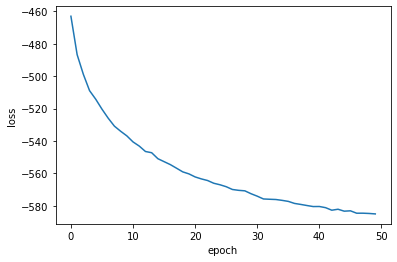

In [41]:
import matplotlib.pyplot as plt

x = [i for i in range(0, len(loss_tracker))]

plt.plot(x, loss_tracker)
plt.xlabel('epoch')
plt.ylabel('loss')

In [42]:
topic_probs, best_topic = slda.get_topic_assignments(phi_hat, pi_hat, document_locs, input_arr, n_docs, c, assignments, sigma, n_topics)

In [43]:
val, count = torch.unique(best_topic, return_counts=True)

In [44]:
colors = ['#15b01a','#0343df', '#ff81c0', '#f97306', '#653700']
color_dict = dict(zip(val.tolist(), colors))
color_assigments = [color_dict[j] for j in best_topic.tolist()]

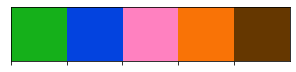

In [45]:
import seaborn as sns 
sns.palplot(colors)

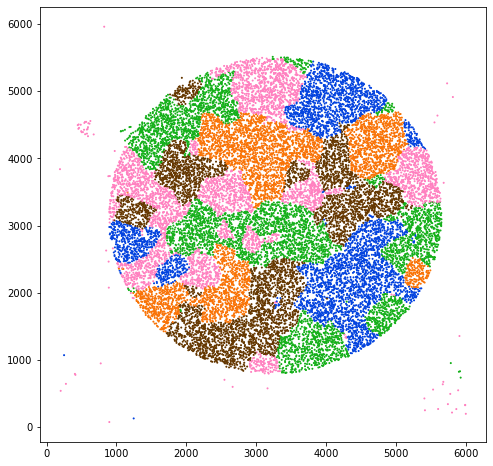

In [46]:
import matplotlib.pyplot as plt

fig_name = '_'.join((f'{PATH_TO_MODELS}/{DATASET_NAME}_{EXPERIMENT_NAME}',
                                f'latentDim={latent_size}',
                                f'lr={lr}',
                                f'topics={n_topics}',
                                f'docs={n_docs}',
                                f'vocab={vocab_size}',
                                f'sigma={sigma}')) + '.pdf'

fig, ax = plt.subplots(1,1, figsize=(8,8))
ax.scatter(x=points[:, 0], y = points[:, 1], c=color_assigments, s = 1)
plt.savefig(fig_name)

### Compare the topics by gene expression

In [28]:
best_topic.shape

torch.Size([20000])

In [30]:
topic_id = 0
idx, = torch.where(best_topic == topic_id)

In [32]:
data[idx, :].shape

torch.Size([3429, 21690])

In [33]:
puck_data.obs

,x,y,n_genes
TAACCTTCGACCCA,3880.1,5392.3,3063
ACACCAGCGTGTCG,4594.6,3566.6,2923
ACGGGACACTACGG,1078.4,3252.8,2872
AACAGTCCACATCT,1919.8,4949.9,2618
AACTTGTTGCTATT,3324.4,2340.0,2317
...,...,...,...
TCTATAAAATAACA,5025.9,4174.7,9
TTAAACCATGCTGA,3056.3,3821.1,10
AAAGTAATTCCAGA,4964.4,3610.8,10
ATACGAAGAAGGAG,4192.9,3421.8,10


In [39]:
puck_data_downsampled = puck_data[loc_df_downsampled.index.tolist()]

In [61]:
puck_data_downsampled.obs['topic_assignment'] = best_topic.numpy()

In [59]:
puck_data_downsampled.obs["topic_assignment"] = puck_data_downsampled.obs["topic_assignment"].astype("category")

In [60]:
sc.tl.rank_genes_groups(puck_data_downsampled, groupby='topic_assignment', key_added='topic_DE_results')

In [96]:
de_genes = sc.get.rank_genes_groups_df(puck_data_downsampled, group='3', key='topic_DE_results')

In [97]:
de_genes.sort_values('scores', ascending=False).iloc[:25, :]

,names,scores,logfoldchanges,pvals,pvals_adj
0,Zg16,9.334553,1.116363,1.501262e-20,5.009597e-18
1,Car4,8.165057,1.978835,4.157307e-16,7.213759e-14
2,mt-Rnr2,7.988987,0.672231,1.628691e-15,2.578563e-13
3,Saa1,7.914589,0.924760,3.034877e-15,4.668545e-13
4,mt-Rnr1,5.809034,0.534185,6.628323e-09,2.677356e-07
5,Tff3,4.806423,0.479223,1.578779e-06,3.300166e-05
6,Prss30,4.339342,1.840911,1.461107e-05,2.144209e-04
7,Sprr2a3,4.266074,0.850505,2.026313e-05,2.797628e-04
8,Prdx6,4.204147,0.451422,2.663574e-05,3.535675e-04
9,Aqp8,4.171562,1.690127,3.082395e-05,3.986711e-04


In [84]:
de_genes.head()

,names,scores,logfoldchanges,pvals,pvals_adj
0,Hsp90b1,12.639149,1.105563,4.674415e-36,2.534702e-32
1,Rpl26,12.511434,1.093943,2.321829e-35,1.007209e-31
2,Eef2,12.493093,1.094642,2.923214e-35,1.056742e-31
3,Camk1d,12.356180,1.214507,1.633688e-34,5.062098e-31
4,Rplp1,12.278885,1.077075,3.863132e-34,9.318951e-31
